In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

data = pd.read_csv("Wholesale customers data.csv")

scaler = StandardScaler()

data_scaled = pd.DataFrame(scaler.fit_transform(data), columns=data.columns)

data_scaled.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(data), columns=data.columns)

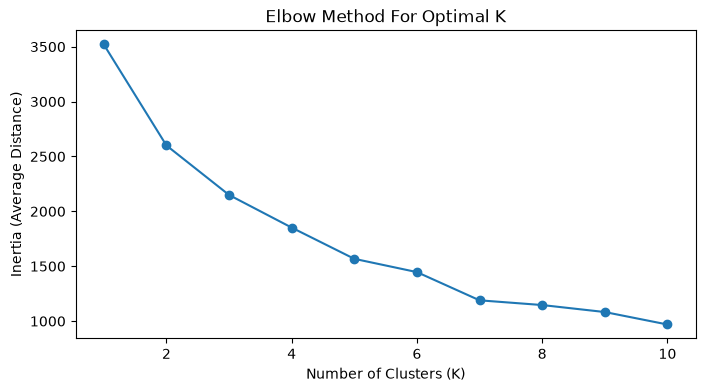

In [7]:
clusters = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42)
    km.fit(data_scaled)
    clusters.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), clusters, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Average Distance)')
plt.title('Elbow Method For Optimal K')
plt.show()

In [8]:
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(data_scaled)
data_scaled['Cluster'] = kmeans.predict(data_scaled)

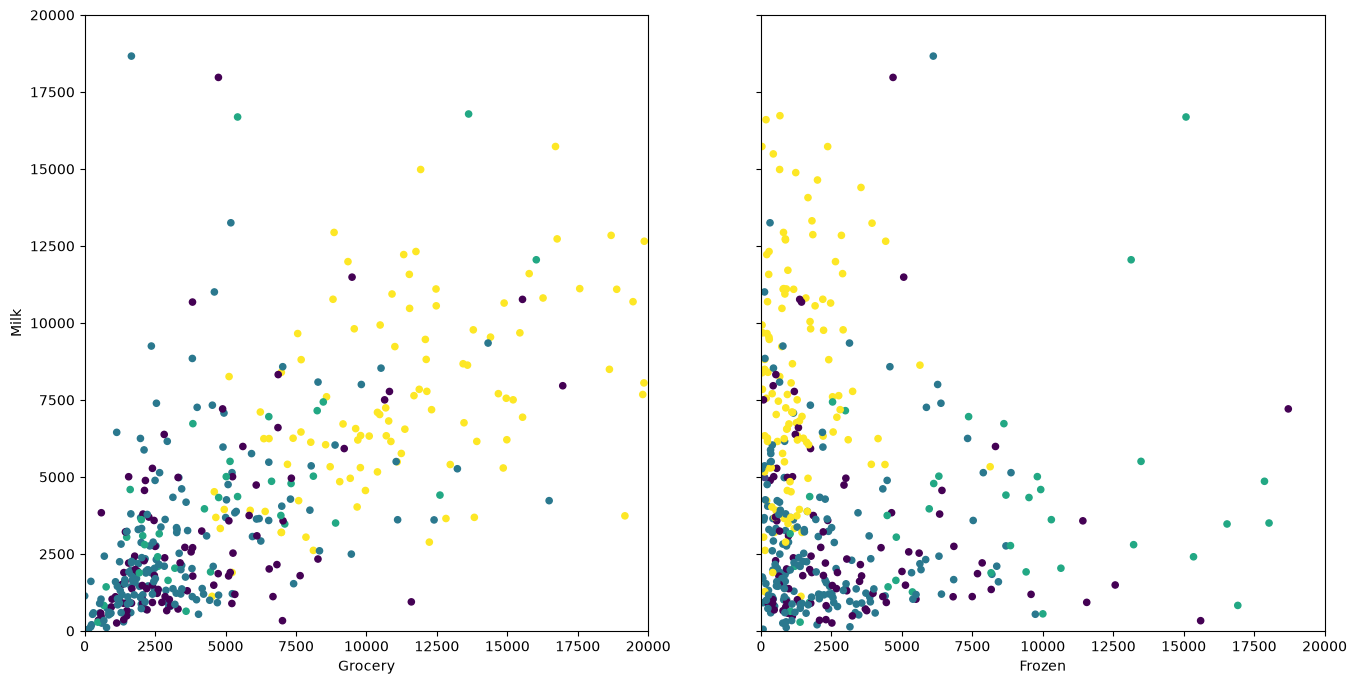

In [10]:
est_kmeans = KMeans(n_clusters=6, random_state=0)
est_kmeans.fit(data_scaled)
pred_kmeans = est_kmeans.predict(data_scaled)

plt.subplots(1, 2, sharex='col', sharey='row', figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.scatter(data.iloc[:, 4], data.iloc[:, 3], c=pred_kmeans, s=20)
plt.xlim([0, 20000])
plt.ylim([0, 20000])
plt.xlabel('Grocery')
plt.ylabel('Milk')

plt.subplot(1, 2, 2)
plt.scatter(data.iloc[:, 5], data.iloc[:, 3], c=pred_kmeans, s=20)
plt.xlim([0, 20000])
plt.ylim([0, 20000])
plt.xlabel('Frozen')

plt.show()